# Exploratory Data Analysis – UCI Bank Marketing Dataset

**BITS Pilani M.Tech (AIML) – Machine Learning Assignment 2 – Student ID: 2026AJ05200**

**Goal of the project:** predict whether a bank client will subscribe to a term deposit (`y` = `yes` / `no`)
based on client attributes and details of the direct-marketing (phone) campaign.

**Source:** UCI Machine Learning Repository – https://archive.ics.uci.edu/dataset/222/bank+marketing
(file `bank-full.csv`, semicolon-separated).

This notebook explores the raw data **before** any modelling. Its findings drive the preprocessing
choices implemented in `src/preprocess.py`.

## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 50)

DATA_PATH = "../data/bank-full.csv"
TARGET_COL = "y"

## 2. Load the original dataset
The file uses `;` as the separator, so `sep=';'` is required.

In [2]:
bank_df = pd.read_csv(DATA_PATH, sep=";")
bank_df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 3. Dataset dimensions

In [3]:
n_rows, n_cols = bank_df.shape
print(f"Instances (rows): {n_rows}")
print(f"Columns         : {n_cols}  (16 input features + 1 target)")

Instances (rows): 45211
Columns         : 17  (16 input features + 1 target)


## 4. Column names

In [4]:
for idx, col in enumerate(bank_df.columns, start=1):
    print(f"{idx:2d}. {col}")

 1. age
 2. job
 3. marital
 4. education
 5. default
 6. balance
 7. housing
 8. loan
 9. contact
10. day
11. month
12. duration
13. campaign
14. pdays
15. previous
16. poutcome
17. y


## 5. Data types

In [5]:
numeric_cols = bank_df.select_dtypes(include="number").columns.tolist()
categorical_cols = [c for c in bank_df.columns if c not in numeric_cols and c != TARGET_COL]

print(f"Numeric features     ({len(numeric_cols)}): {numeric_cols}")
print(f"Categorical features ({len(categorical_cols)}): {categorical_cols}")
print()
bank_df.info()

Numeric features     (7): ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
Categorical features (9): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  


## 6. Missing values
First check for real missing values (NaN), then for the placeholder text `"unknown"`,
which this dataset uses instead of blanks.

In [6]:
nan_counts = bank_df.isna().sum()
print("Total NaN values in the dataset:", int(nan_counts.sum()))

unknown_summary = (
    (bank_df[categorical_cols] == "unknown")
    .sum()
    .to_frame("unknown_count")
    .assign(unknown_pct=lambda d: (d["unknown_count"] / n_rows * 100).round(2))
    .query("unknown_count > 0")
    .sort_values("unknown_count", ascending=False)
)
unknown_summary

Total NaN values in the dataset: 0


,unknown_count,unknown_pct
poutcome,36959,81.75
contact,13020,28.80
education,1857,4.11
job,288,0.64


## 7. Duplicate records

In [7]:
dup_count = bank_df.duplicated().sum()
print(f"Fully duplicated rows: {dup_count}")

Fully duplicated rows: 0


## 8. Target variable distribution

,count,percent
y,,
no,39922,88.3
yes,5289,11.7


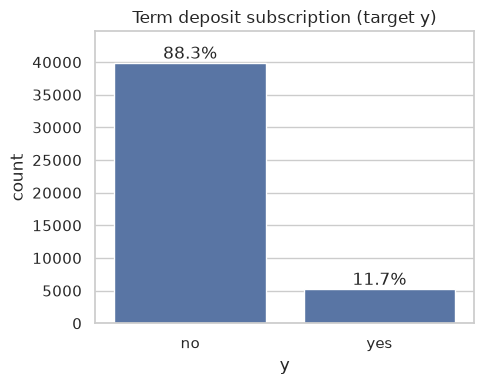

Accuracy of always predicting the majority class: 88.3%


In [8]:
target_counts = bank_df[TARGET_COL].value_counts()
target_pct = bank_df[TARGET_COL].value_counts(normalize=True).mul(100).round(2)
display(pd.DataFrame({"count": target_counts, "percent": target_pct}))

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=bank_df, x=TARGET_COL, order=["no", "yes"], ax=ax)
for patch, pct in zip(ax.patches, target_pct.reindex(["no", "yes"])):
    ax.annotate(f"{pct}%", (patch.get_x() + patch.get_width() / 2, patch.get_height()),
                ha="center", va="bottom")
ax.set_title("Term deposit subscription (target y)")
ax.margins(y=0.12)
plt.tight_layout()
plt.show()

majority_baseline = target_pct.max()
print(f"Accuracy of always predicting the majority class: {majority_baseline}%")

## 9. Numerical features – summary statistics

In [9]:
num_summary = bank_df[numeric_cols].describe().T
num_summary["skewness"] = bank_df[numeric_cols].skew().round(2)
num_summary.round(2)

,count,mean,std,min,25%,50%,75%,max,skewness
age,45211.0,40.94,10.62,18.0,33.0,39.0,48.0,95.0,0.68
balance,45211.0,1362.27,3044.77,-8019.0,72.0,448.0,1428.0,102127.0,8.36
day,45211.0,15.81,8.32,1.0,8.0,16.0,21.0,31.0,0.09
duration,45211.0,258.16,257.53,0.0,103.0,180.0,319.0,4918.0,3.14
campaign,45211.0,2.76,3.10,1.0,1.0,2.0,3.0,63.0,4.90
pdays,45211.0,40.20,100.13,-1.0,-1.0,-1.0,-1.0,871.0,2.62
previous,45211.0,0.58,2.30,0.0,0.0,0.0,0.0,275.0,41.85


In [10]:
# pdays = -1 means the client was never contacted in a previous campaign
never_contacted = (bank_df["pdays"] == -1).mean() * 100
zero_previous = (bank_df["previous"] == 0).mean() * 100
negative_balance = (bank_df["balance"] < 0).mean() * 100
print(f"pdays == -1 (never contacted before): {never_contacted:.2f}%")
print(f"previous == 0                        : {zero_previous:.2f}%")
print(f"balance < 0                          : {negative_balance:.2f}%")

pdays == -1 (never contacted before): 81.74%
previous == 0                        : 81.74%
balance < 0                          : 8.33%


## 10. Numerical feature distributions

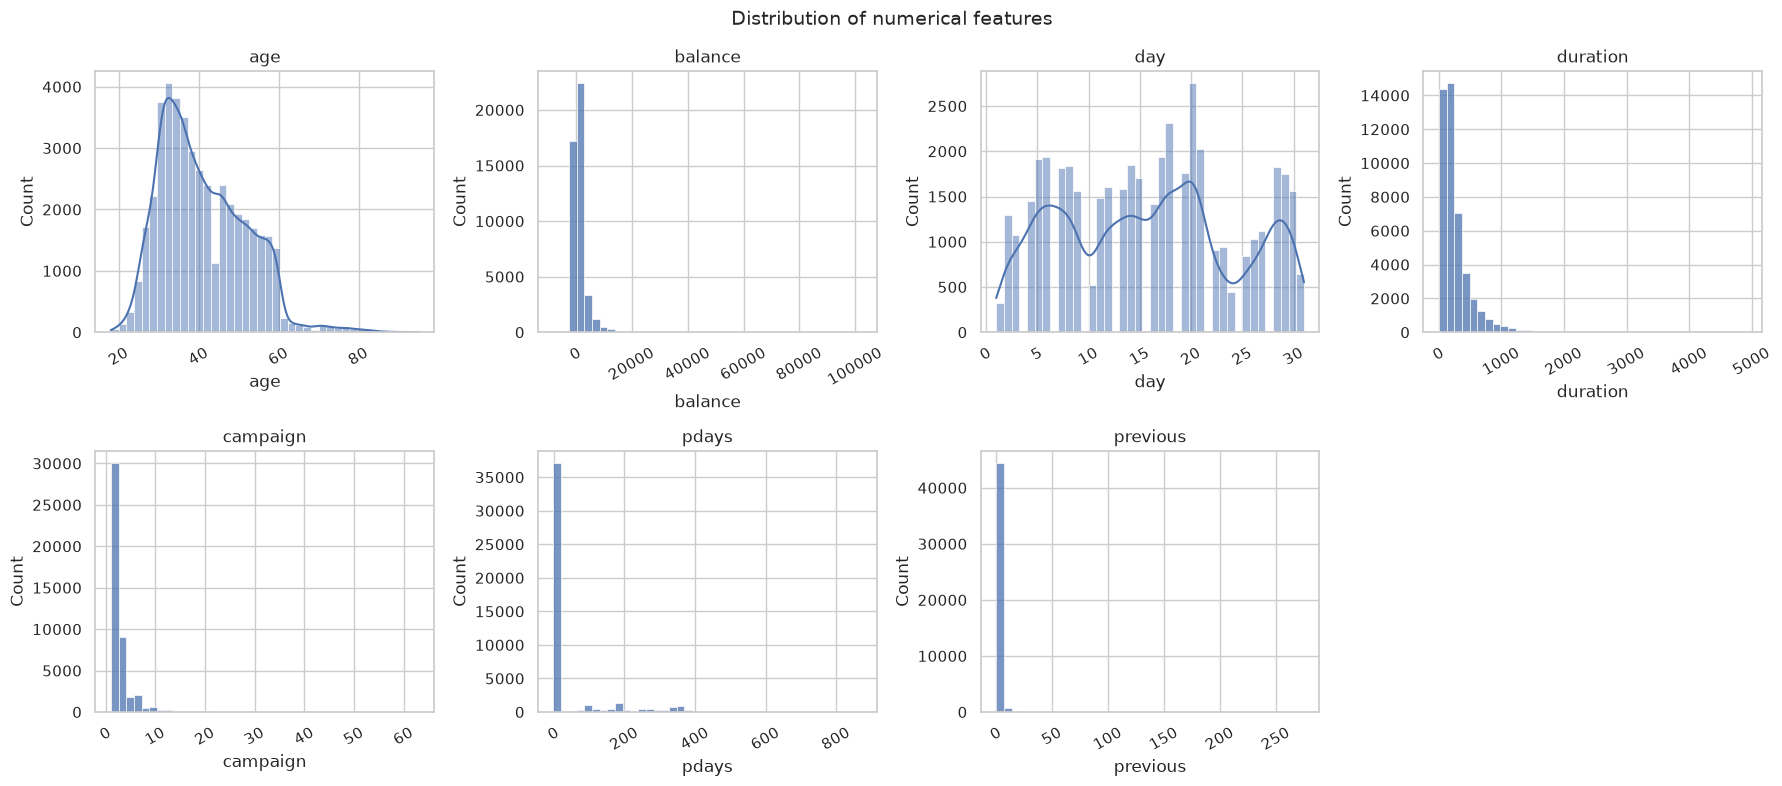

In [11]:
# KDE only for roughly symmetric features: on very skewed ones the curve spikes far above the bars
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, numeric_cols):
    sns.histplot(bank_df[col], bins=40, kde=abs(bank_df[col].skew()) < 1, ax=ax)
    ax.set_title(col)
    ax.tick_params(axis="x", labelrotation=30)
axes.flat[-1].set_visible(False)
fig.suptitle("Distribution of numerical features", fontsize=14)
plt.tight_layout()
plt.show()

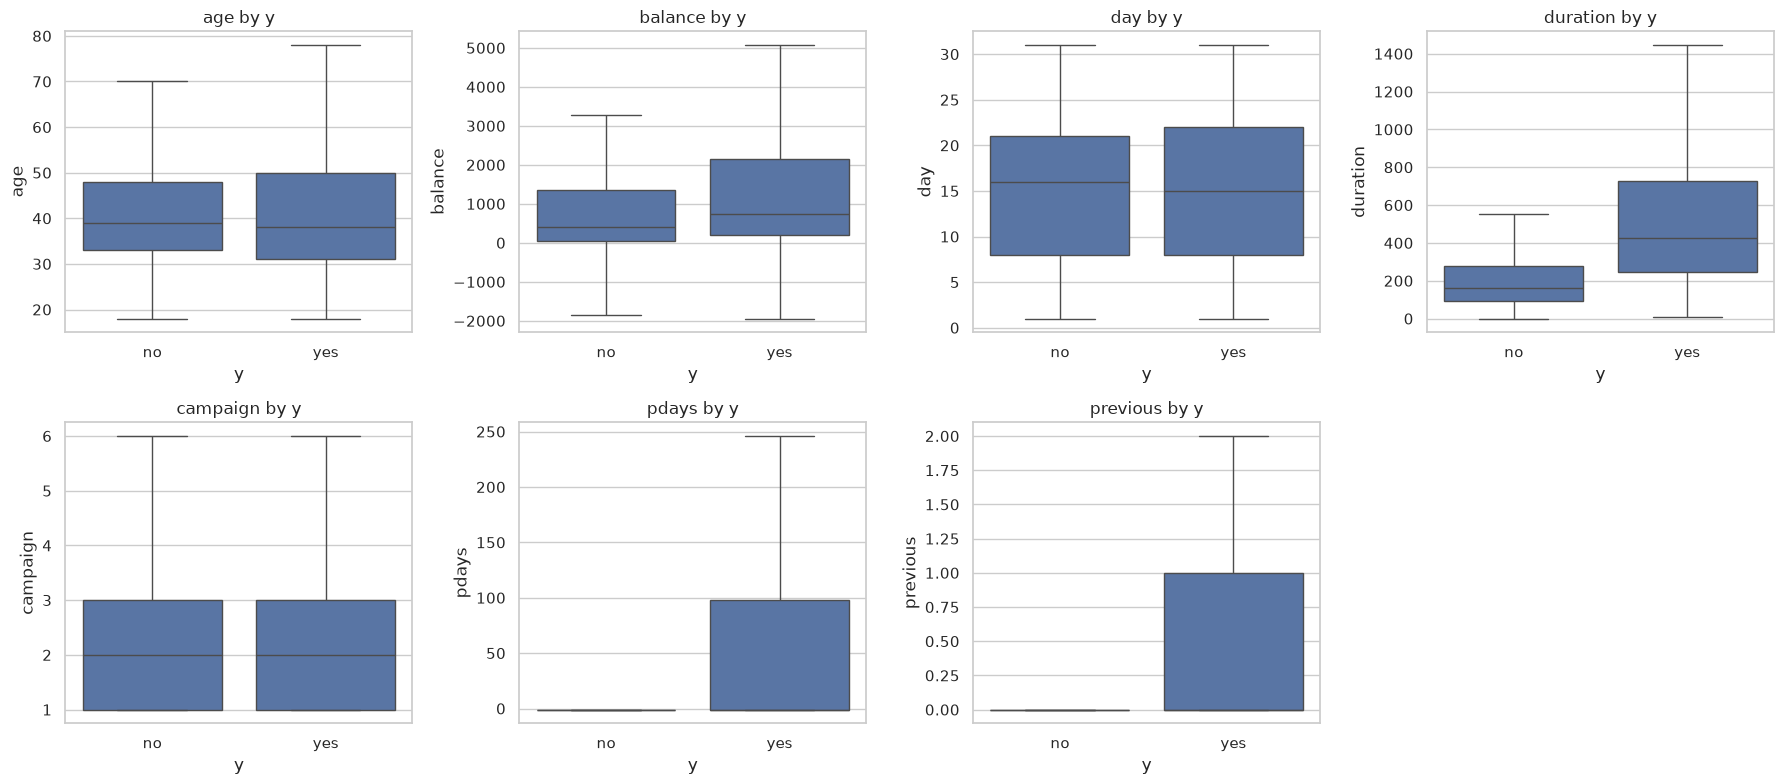

y,no,yes
age,39.0,38.0
balance,417.0,733.0
day,16.0,15.0
duration,164.0,426.0
campaign,2.0,2.0
pdays,-1.0,-1.0
previous,0.0,0.0


In [12]:
# Same features split by target class to see which ones separate yes / no
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, numeric_cols):
    sns.boxplot(data=bank_df, x=TARGET_COL, y=col, order=["no", "yes"], ax=ax, showfliers=False)
    ax.set_title(f"{col} by y")
axes.flat[-1].set_visible(False)
plt.tight_layout()
plt.show()

bank_df.groupby(TARGET_COL)[numeric_cols].median().T

## 11. Categorical features – summary

In [13]:
cat_summary = pd.DataFrame({
    "unique_values": bank_df[categorical_cols].nunique(),
    "most_frequent": bank_df[categorical_cols].mode().iloc[0],
    "most_frequent_pct": [
        round(bank_df[c].value_counts(normalize=True).iloc[0] * 100, 2) for c in categorical_cols
    ],
})
cat_summary

,unique_values,most_frequent,most_frequent_pct
job,12,blue-collar,21.53
marital,3,married,60.19
education,4,secondary,51.32
default,2,no,98.20
housing,2,yes,55.58
loan,2,no,83.98
contact,3,cellular,64.77
month,12,may,30.45
poutcome,4,unknown,81.75


## 12. Categorical feature distributions

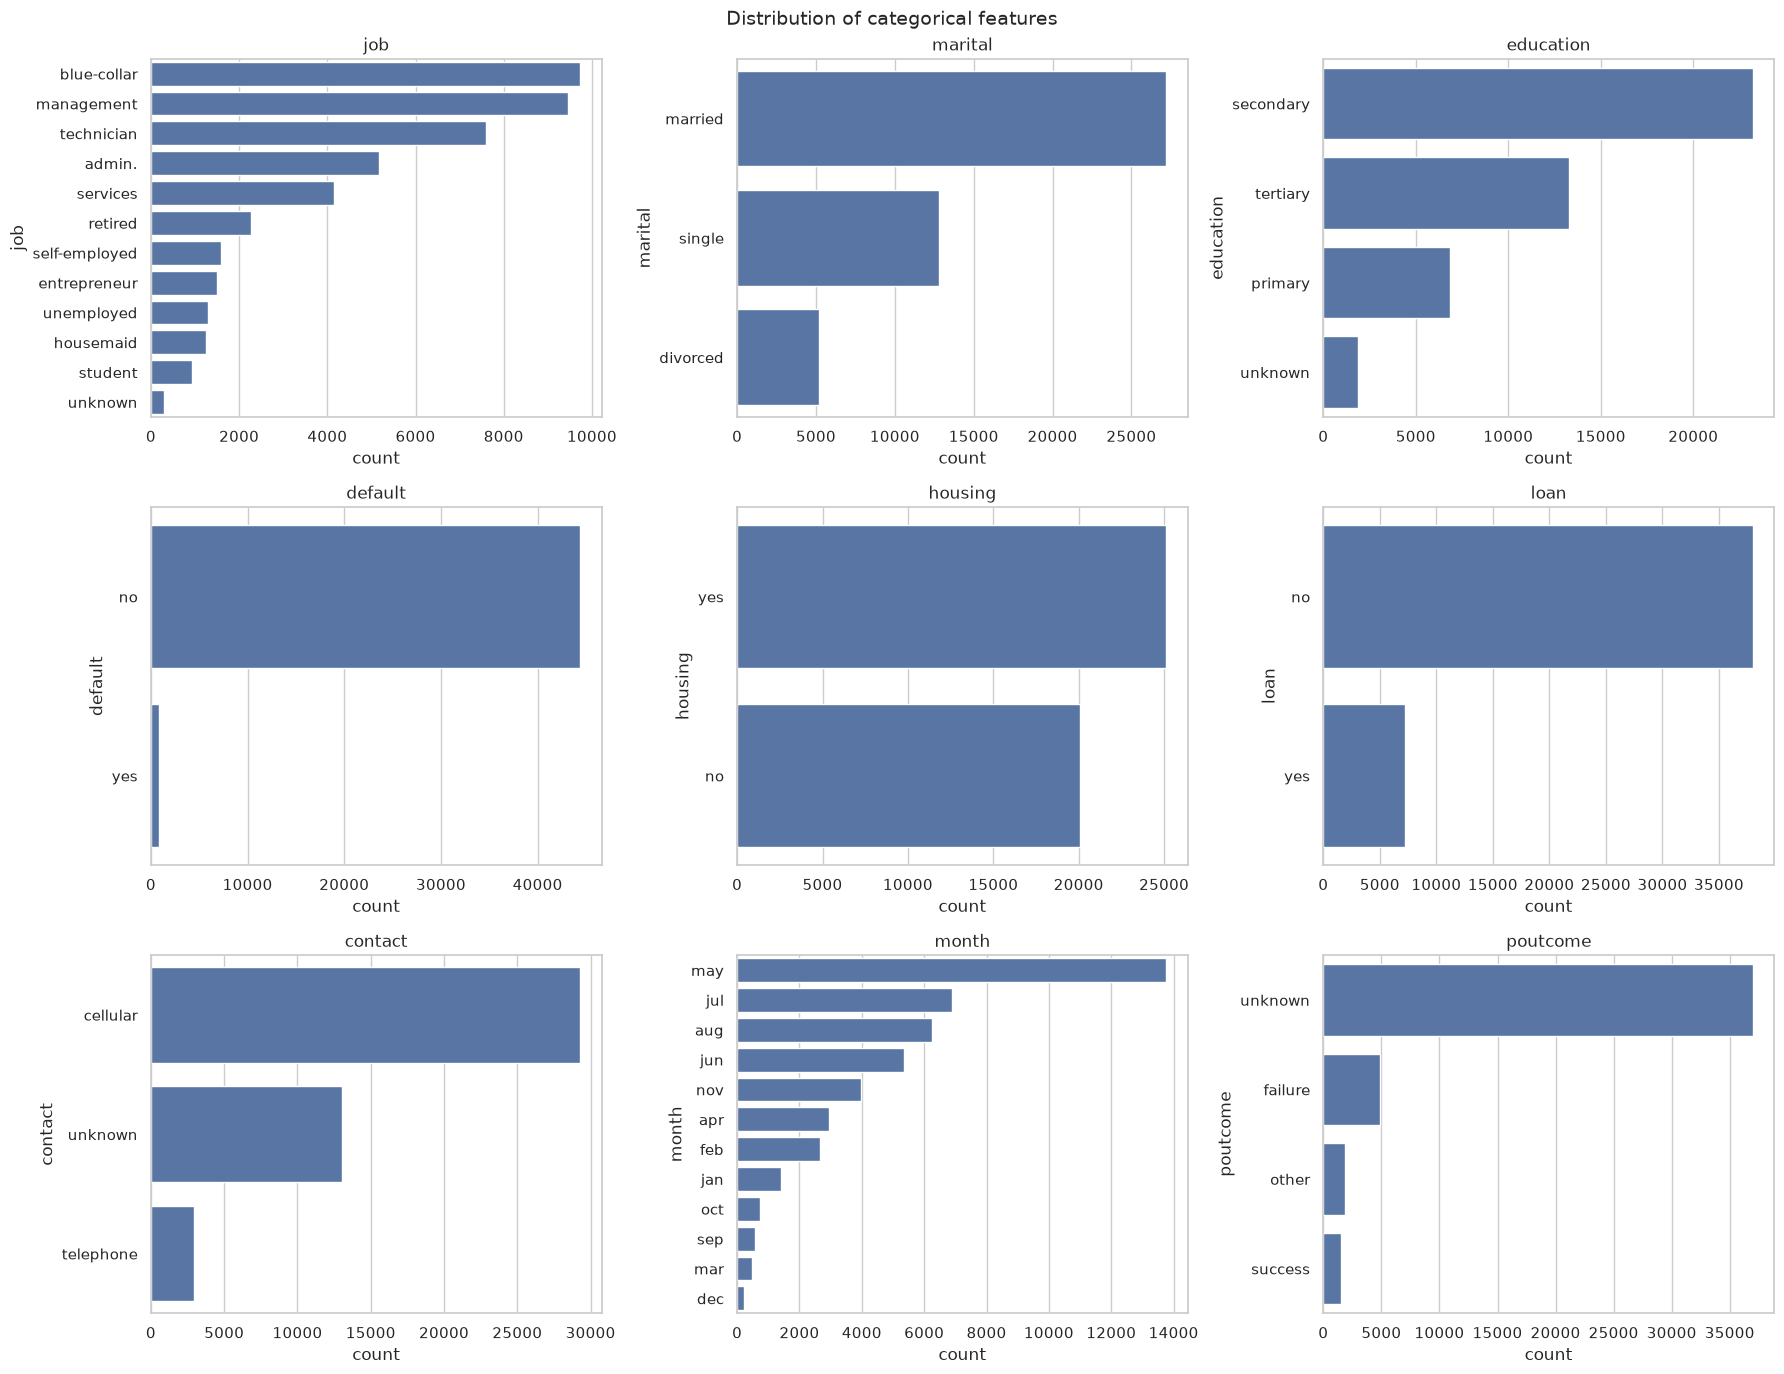

In [14]:
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
for ax, col in zip(axes.flat, categorical_cols):
    order = bank_df[col].value_counts().index
    sns.countplot(data=bank_df, y=col, order=order, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("count")
fig.suptitle("Distribution of categorical features", fontsize=14)
plt.tight_layout()
plt.show()

### 12.1 Subscription rate (% of `yes`) within each category

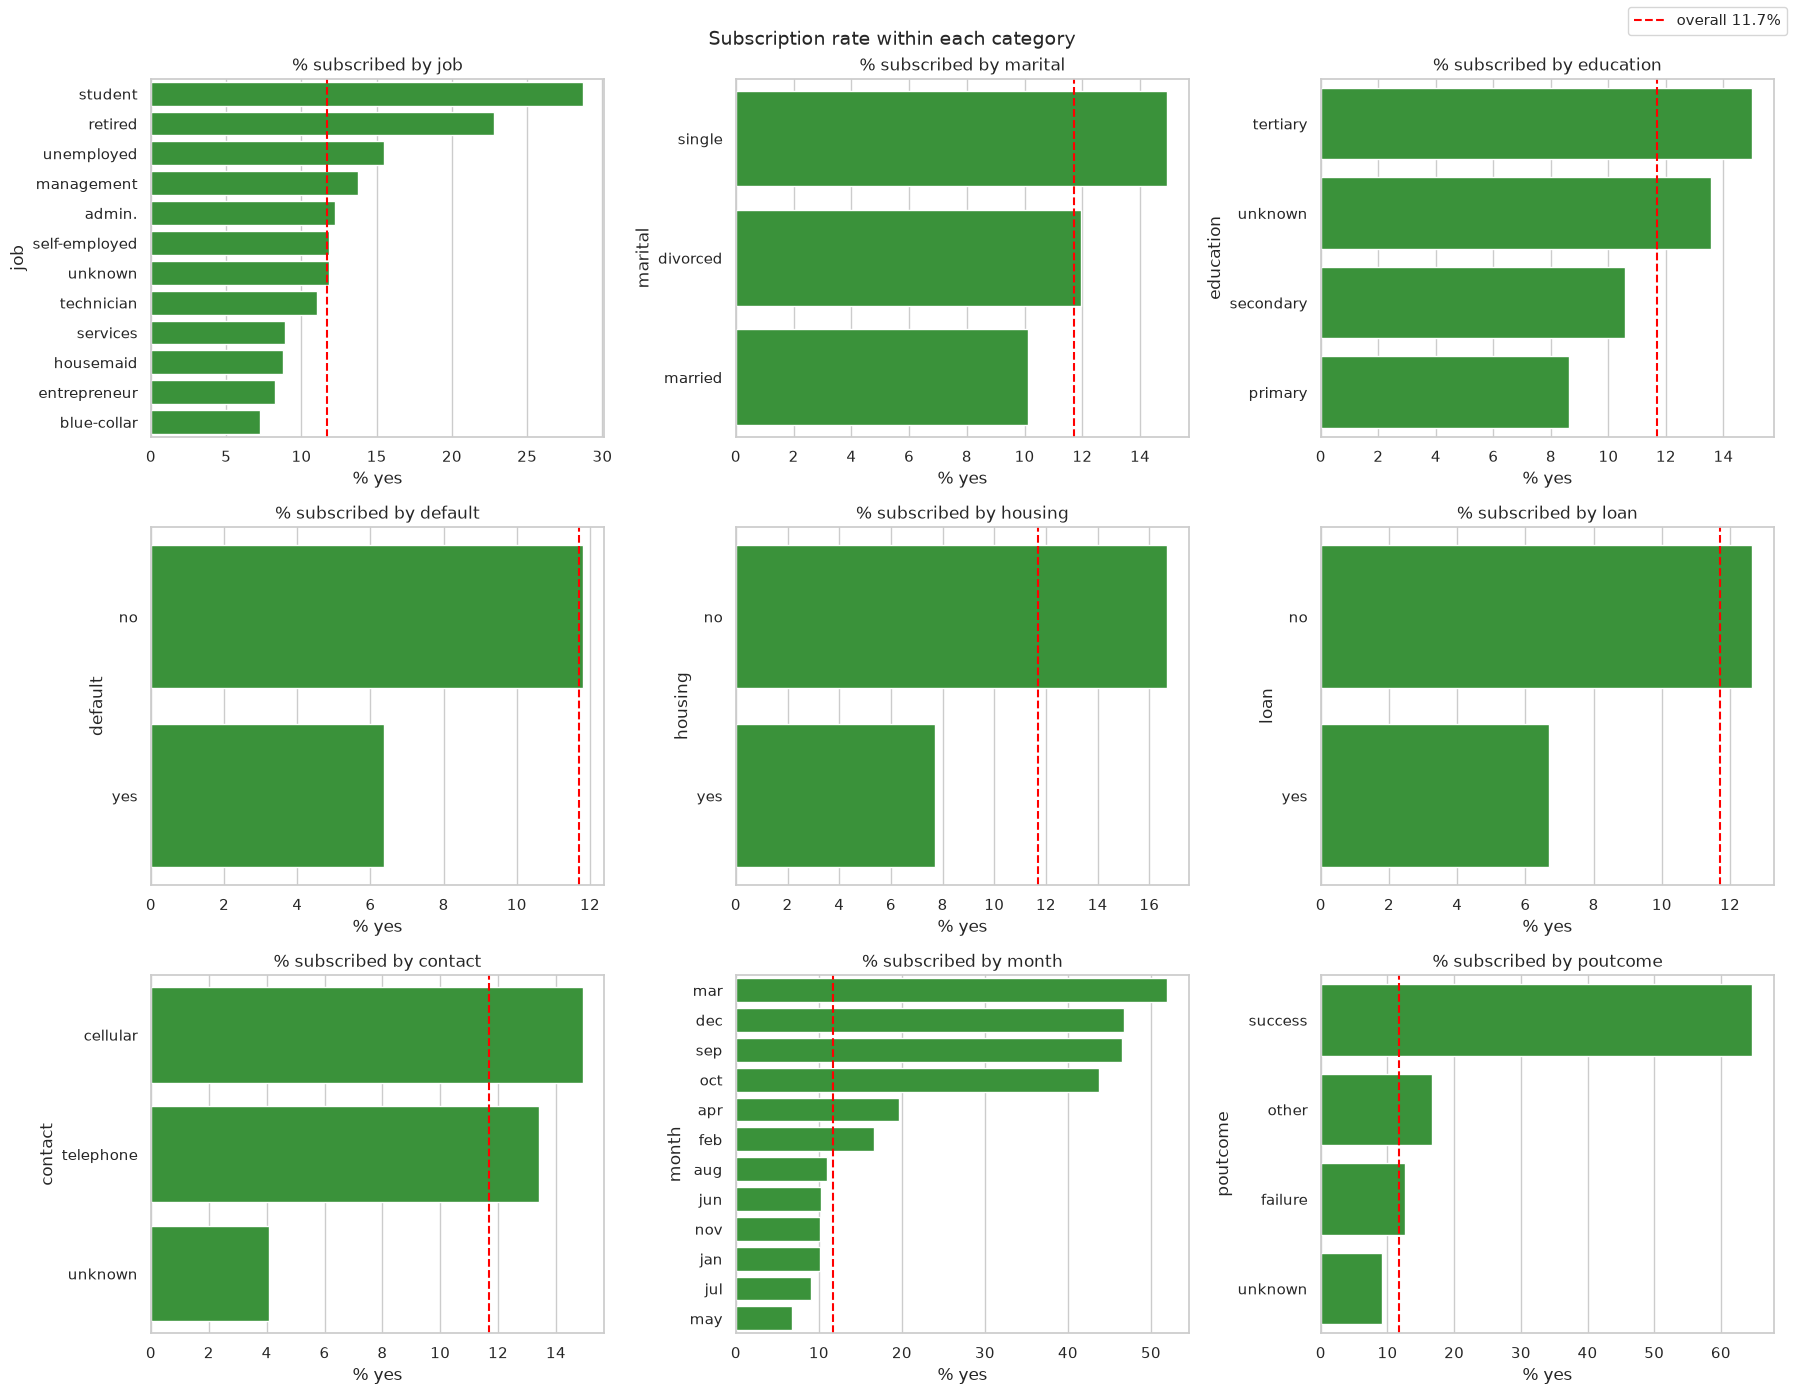

In [15]:
yes_flag = (bank_df[TARGET_COL] == "yes").astype(int)
overall_rate = yes_flag.mean() * 100

fig, axes = plt.subplots(3, 3, figsize=(18, 14))
for ax, col in zip(axes.flat, categorical_cols):
    rate = yes_flag.groupby(bank_df[col]).mean().mul(100).sort_values(ascending=False)
    sns.barplot(x=rate.values, y=rate.index, ax=ax, color="tab:green")
    ax.axvline(overall_rate, color="red", linestyle="--", label=f"overall {overall_rate:.1f}%")
    ax.set_title(f"% subscribed by {col}")
    ax.set_xlabel("% yes")
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right")
fig.suptitle("Subscription rate within each category", fontsize=14)
plt.tight_layout()
plt.show()

In [16]:
# Strongest categories (highest and lowest subscription rate) for each feature
rate_rows = []
for col in categorical_cols:
    rate = yes_flag.groupby(bank_df[col]).mean().mul(100)
    rate_rows.append({
        "feature": col,
        "highest_category": rate.idxmax(), "highest_yes_pct": round(rate.max(), 2),
        "lowest_category": rate.idxmin(), "lowest_yes_pct": round(rate.min(), 2),
        "spread_pct_points": round(rate.max() - rate.min(), 2),
    })
pd.DataFrame(rate_rows).sort_values("spread_pct_points", ascending=False)

,feature,highest_category,highest_yes_pct,lowest_category,lowest_yes_pct,spread_pct_points
8,poutcome,success,64.73,unknown,9.16,55.56
7,month,mar,51.99,may,6.72,45.27
0,job,student,28.68,blue-collar,7.27,21.40
6,contact,cellular,14.92,unknown,4.07,10.85
4,housing,no,16.70,yes,7.70,9.00
2,education,tertiary,15.01,primary,8.63,6.38
5,loan,no,12.66,yes,6.68,5.97
3,default,no,11.80,yes,6.38,5.42
1,marital,single,14.95,married,10.12,4.83


### 12.2 Subscription rate by month and by age band
Month is the categorical feature with the largest spread; age is numerical, so it is grouped into bands here.

In [17]:
month_rate = yes_flag.groupby(bank_df["month"]).mean().mul(100).round(2).sort_values(ascending=False)
display(month_rate.to_frame("yes_pct").T)

age_band = pd.cut(bank_df["age"], bins=[17, 25, 35, 55, 65, 95],
                  labels=["18-25", "26-35", "36-55", "56-65", "66-95"])
age_rate = pd.DataFrame({
    "clients": age_band.value_counts().sort_index(),
    "yes_pct": yes_flag.groupby(age_band, observed=True).mean().mul(100).round(2),
})
age_rate

month,mar,dec,sep,oct,apr,feb,aug,jun,nov,jan,jul,may
yes_pct,51.99,46.73,46.46,43.77,19.68,16.65,11.01,10.22,10.15,10.12,9.09,6.72


,clients,yes_pct
age,,
18-25,1336,23.95
26-35,15571,12.00
36-55,23404,9.37
56-65,4149,14.12
66-95,751,42.61


## 13. Correlation analysis
Pearson correlation between the numerical features, plus each feature's correlation with
the target encoded as `yes = 1`, `no = 0`.

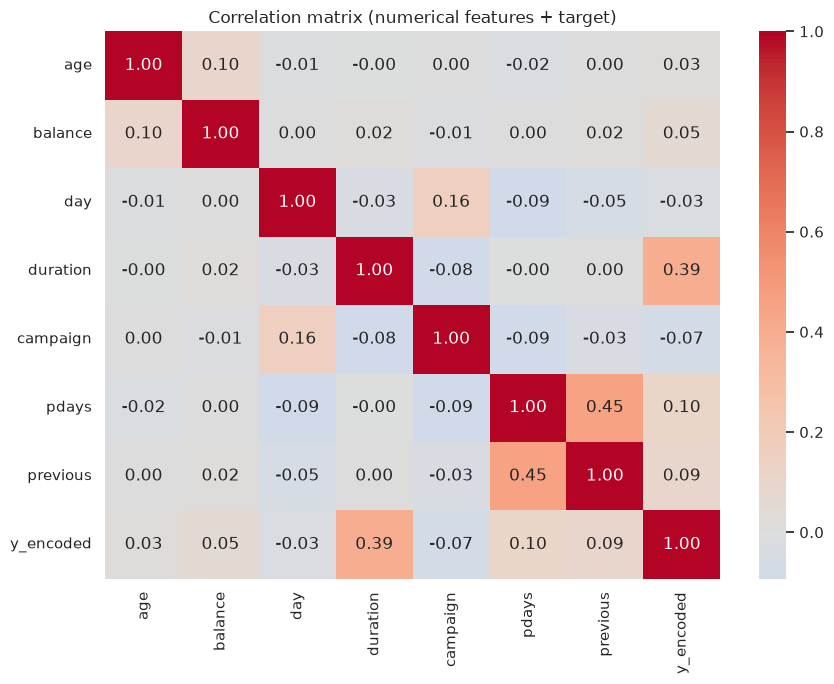

duration    0.395
pdays       0.104
previous    0.093
campaign   -0.073
balance     0.053
day        -0.028
age         0.025
Name: y_encoded, dtype: float64

In [18]:
corr_df = bank_df[numeric_cols].assign(y_encoded=yes_flag)
corr_matrix = corr_df.corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation matrix (numerical features + target)")
plt.tight_layout()
plt.show()

corr_matrix["y_encoded"].drop("y_encoded").sort_values(key=abs, ascending=False).round(3)

## 14. Outlier detection (IQR rule)
A value is flagged as an outlier if it is below Q1 − 1.5·IQR or above Q3 + 1.5·IQR.

In [19]:
outlier_rows = []
for col in numeric_cols:
    q1, q3 = bank_df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((bank_df[col] < low) | (bank_df[col] > high)).sum()
    outlier_rows.append({"feature": col, "Q1": q1, "Q3": q3, "lower_fence": low,
                         "upper_fence": high, "outliers": n_out,
                         "outlier_pct": round(n_out / n_rows * 100, 2)})
outlier_df = pd.DataFrame(outlier_rows).sort_values("outliers", ascending=False)
outlier_df

,feature,Q1,Q3,lower_fence,upper_fence,outliers,outlier_pct
6,previous,0.0,0.0,0.0,0.0,8257,18.26
5,pdays,-1.0,-1.0,-1.0,-1.0,8257,18.26
1,balance,72.0,1428.0,-1962.0,3462.0,4729,10.46
3,duration,103.0,319.0,-221.0,643.0,3235,7.16
4,campaign,1.0,3.0,-2.0,6.0,3064,6.78
0,age,33.0,48.0,10.5,70.5,487,1.08
2,day,8.0,21.0,-11.5,40.5,0,0.00


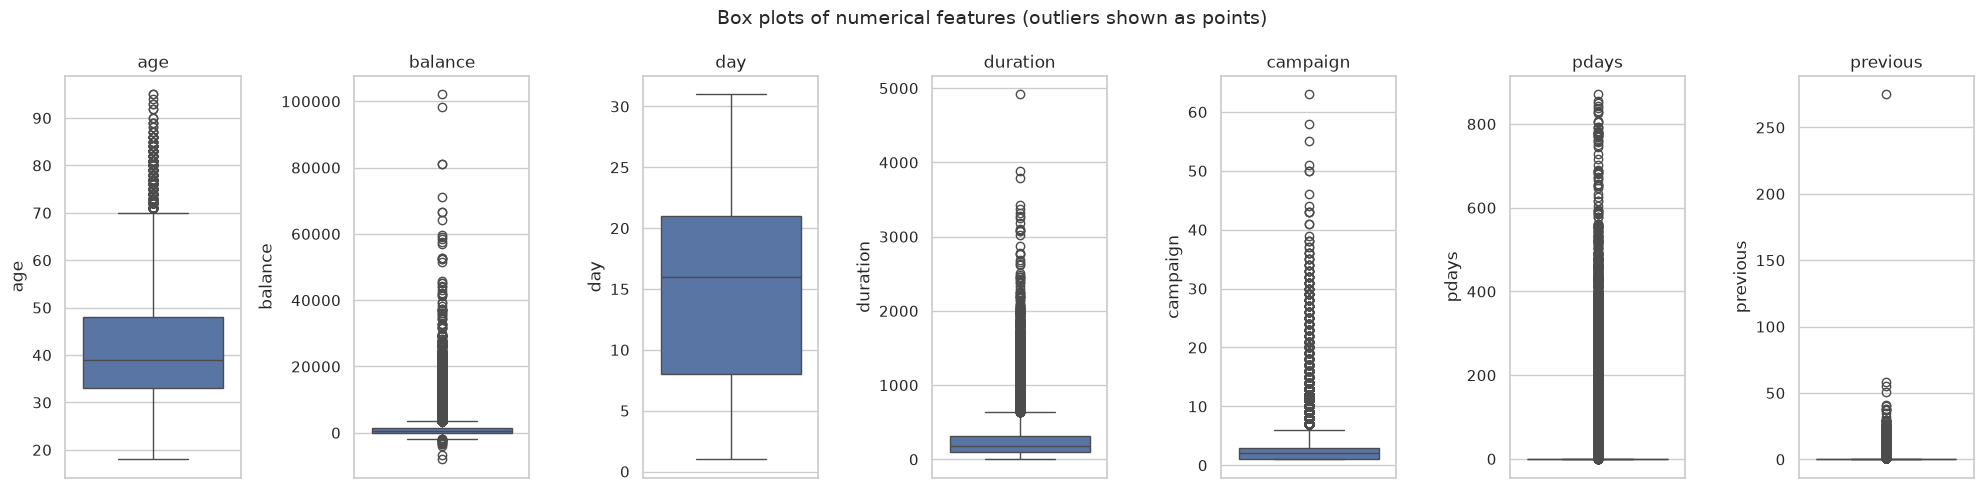

In [20]:
fig, axes = plt.subplots(1, len(numeric_cols), figsize=(20, 5))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(y=bank_df[col], ax=ax)
    ax.set_title(col)
fig.suptitle("Box plots of numerical features (outliers shown as points)", fontsize=14)
plt.tight_layout()
plt.show()

## 15. Data-leakage check: `duration`
The UCI dataset description notes that `duration` (length of the last call, in seconds) strongly
affects the target, but it is **only known after the call has ended**, when the outcome is already
known. A model meant to decide *whom to call* cannot use it.

In [21]:
display(bank_df.groupby(TARGET_COL)["duration"].describe().round(1))
print(f"Correlation of duration with y: {corr_matrix.loc['duration', 'y_encoded']:.3f}")
print(f"Calls with duration == 0 that ended in 'yes': "
      f"{((bank_df['duration'] == 0) & (bank_df[TARGET_COL] == 'yes')).sum()}")

,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
no,39922.0,221.2,207.4,0.0,95.0,164.0,279.0,4918.0
yes,5289.0,537.3,392.5,8.0,244.0,426.0,725.0,3881.0


Correlation of duration with y: 0.395
Calls with duration == 0 that ended in 'yes': 0


## 16. Final feature set used for modelling

In [22]:
DROPPED_FEATURES = ["duration"]
model_numeric = [c for c in numeric_cols if c not in DROPPED_FEATURES]
model_categorical = categorical_cols
model_features = model_numeric + model_categorical

print(f"Numeric features used     ({len(model_numeric)}): {model_numeric}")
print(f"Categorical features used ({len(model_categorical)}): {model_categorical}")
print(f"Total input features      : {len(model_features)}  (assignment minimum = 12)")
assert len(model_features) >= 12

# The training code must use exactly this feature set
import sys
sys.path.insert(0, "..")
from src.preprocess import CATEGORICAL_FEATURES, NUMERICAL_FEATURES

assert model_numeric == NUMERICAL_FEATURES and model_categorical == CATEGORICAL_FEATURES
print("Same feature lists as src/preprocess.py")

Numeric features used     (6): ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
Categorical features used (9): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
Total input features      : 15  (assignment minimum = 12)
Same feature lists as src/preprocess.py


## 17. Key observations

All numbers below come from the outputs above.

**Data quality**
1. The dataset has **45,211 rows and 17 columns** (16 input features + target `y`), i.e. 7 numeric and 9 categorical features.
2. There are **no NaN values and no duplicate rows**, so no rows need to be removed or imputed.
3. Missing information is encoded as the text `"unknown"`: `poutcome` 81.75%, `contact` 28.80%, `education` 4.11%, `job` 0.64%.
   These are kept as a **separate category** because "unknown" is itself informative
   (e.g. `contact = unknown` has only a 4.07% subscription rate vs 14.92% for `cellular`).

**Target**
4. The target is **imbalanced: 88.3% `no` vs 11.7% `yes`**. Always predicting `no` would already give 88.3% accuracy,
   so accuracy alone is misleading. Models are therefore compared on **AUC, F1, Recall, Precision and MCC** as well,
   with `yes` as the positive class, and stratified splitting plus class weighting are used.

**Numerical features**
5. `previous`, `balance`, `campaign`, `duration` and `pdays` are **strongly right-skewed** (skewness 41.85, 8.36, 4.90, 3.14, 2.62).
   `age` (0.68) and `day` (0.09) are close to symmetric. 8.33% of clients have a negative balance.
6. `pdays = -1` and `previous = 0` both occur in **81.74%** of rows (client never contacted in a previous campaign),
   which matches `poutcome = unknown` (81.75%).
7. Clients who subscribed have a higher median balance (733 vs 417).
   Median age (38 vs 39), day (15 vs 16) and campaign (2 vs 2) are almost identical for both classes.
8. Correlations between numeric features and `y` are weak. Apart from `duration` (0.395), the largest are `pdays` (0.104) and `previous` (0.093).
   The only notable correlation between input features is `pdays`/`previous` (0.45, moderate); every other pair is ≤ 0.16, so multicollinearity is not a concern.

**Categorical features**
9. The categorical features separate the classes much better than the numeric ones:
   - `poutcome = success` → **64.73%** subscribe (vs 9.16% for `unknown`), the strongest single signal.
   - `month`: March, December, September and October convert at 43.77–51.99% (March 51.99%), but May only 6.72%, although May is the busiest month (30.45% of calls).
   - Age is U-shaped: 42.61% of clients aged 66–95 and 23.95% of those aged 18–25 subscribe, versus 9.37% for ages 36–55.
   - `job`: students (28.68%) and retired clients (22.79%) subscribe most, blue-collar workers least (7.27%).
   - Clients **without** a housing loan (16.70%) or personal loan (12.66%) subscribe more often than those with one (7.70% / 6.68%).
10. `default` is almost constant (98.20% `no`), so it carries little information but is kept (it is a legitimate input).

**Outliers**
11. The IQR rule flags many points in `balance` (10.46%), `campaign` (6.78%) and `age` (1.08%). For `pdays` and `previous`
    the fences collapse to a single value because more than 75% of rows are -1 / 0, so every previously contacted client (18.26%) is "flagged".
12. These are **genuine values, not data-entry errors** (large balances, many call attempts), so they are **not removed**.
    `StandardScaler` is applied to the numeric features, and the decision tree is insensitive to outliers.

**Data leakage**
13. `duration` has by far the highest correlation with `y` (0.395), and the median call for `yes` lasts 426 s vs 164 s for `no`.
    But the duration is only known **after** the call ends, when the outcome is already decided. Keeping it would inflate every metric
    and make the model useless for deciding whom to call. **`duration` is therefore dropped**, as recommended in the UCI description.

**Resulting modelling setup**
14. **15 input features** (6 numeric + 9 categorical), above the assignment minimum of 12.
    Numeric → median imputation + standard scaling; categorical → one-hot encoding (with `"unknown"` as a category);
    stratified 80/20 train/test split. These steps are implemented in `src/preprocess.py`.